<a href="https://colab.research.google.com/github/FPetterini/econometria/blob/main/Logit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logit

**Econometria I · Capítulo 15**

**Referência:** Gujarati e Porter (2011), seções 15.5–15.8; dados da Tabela 15.7 (p. 559) e estimação logit da Tabela 15.8 (p. 560).

In [1]:
import importlib.util
import subprocess
import sys
if importlib.util.find_spec("statsmodels") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "statsmodels"])

from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm, poisson
from scipy.special import expit
from IPython.display import display, HTML

%matplotlib inline
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 12)
print("Ambiente pronto. Execute as células na ordem.")

Ambiente pronto. Execute as células na ordem.


## 1. Retomando a pergunta


Usaremos os mesmos **32 estudantes da Tabela 15.7**, de Spector e Mazzeo (1980), mantendo os valores originais do livro.

| Variável | Significado | Analogia para entender no Brasil |
|---|---|---|
| `Y` | 1 para conceito A; 0 para B ou C | Indicador de desempenho elevado. Como analogia, nota final de pelo menos 9; esse corte não foi aplicado aos dados. |
| `GPA` | Desempenho acadêmico anterior, em escala norte-americana de pontos | Semelhante a um índice de aproveitamento. GPA = 3,2 não equivale a nota 3,2 na escala brasileira de 0 a 10. |
| `TUCE` | Pontos em um teste inicial de conhecimentos de Economia | Uma prova de nivelamento ou pré-teste; os pontos não estão em escala de 0 a 10. |
| `PSI` | 1 para participação no método alternativo de ensino; 0 caso contrário | Indicador do método usado na disciplina, e não uma nota. |

`Y = 0` não significa nota zero ou reprovação: apenas um conceito diferente de A. GPA e TUCE descrevem a preparação anterior; PSI identifica o método. As analogias brasileiras não alteram a base.


Na aula anterior, usamos $E(Y\mid X)=P(Y=1\mid X)$ e estimamos essa probabilidade por uma reta. Encontramos cinco valores ajustados negativos. Agora queremos manter a interpretação probabilística com uma função que fique entre 0 e 1.

In [2]:
# Valores da Tabela 15.7. Cada linha representa um estudante.
csv_estudantes = """GPA,TUCE,PSI,Y
2.66,20,0,0
2.89,22,0,0
3.28,24,0,0
2.92,12,0,0
4.00,21,0,1
2.86,17,0,0
2.76,17,0,0
2.87,21,0,0
3.03,25,0,0
3.92,29,0,1
2.63,20,0,0
3.32,23,0,0
3.57,23,0,0
3.26,25,0,1
3.53,26,0,0
2.74,19,0,0
2.75,25,0,0
2.83,19,0,0
3.12,23,1,0
3.16,25,1,1
2.06,22,1,0
3.62,28,1,1
2.89,14,1,0
3.51,26,1,0
3.54,24,1,1
2.83,27,1,1
3.39,17,1,1
2.67,24,1,0
3.65,21,1,1
4.00,23,1,1
3.10,21,1,0
2.39,19,1,1
"""

dados = pd.read_csv(StringIO(csv_estudantes))
dados.index = pd.RangeIndex(1, len(dados) + 1, name="Estudante")
print(f"Número de estudantes: {len(dados)}")
display(dados.head(6))

Número de estudantes: 32


,GPA,TUCE,PSI,Y
Estudante,,,,
1,2.66,20,0,0
2,2.89,22,0,0
3,3.28,24,0,0
4,2.92,12,0,0
5,4.00,21,0,1
6,2.86,17,0,0


In [3]:
regressores = ["GPA", "TUCE", "PSI"]
X = sm.add_constant(dados[regressores], has_constant="add")
y = dados["Y"]
mpl = sm.OLS(y, X).fit()
print(f"MPL: {int((mpl.fittedvalues < 0).sum())} previsões negativas.")

MPL: 5 previsões negativas.


## 2. Uma curva para representar probabilidades

### Primeiro, construímos um índice

O índice $z_i=\beta_1+\beta_2GPA_i+\beta_3TUCE_i+\beta_4PSI_i$ pode ser negativo ou positivo e não tem, por si só, a unidade de uma probabilidade. No logit, passamos esse índice pela **função logística**:

$$p_i=P(Y_i=1\mid X_i)=\frac{1}{1+\exp(-z_i)}.$$

Para qualquer índice finito, o resultado fica entre 0 e 1. Se $z_i=0$, temos $p_i=0{,}5$. Índices muito negativos produzem probabilidades próximas de zero; muito positivos, próximas de um.

A relação tem formato de S: aumentos no índice pouco alteram a probabilidade perto dos extremos e alteram mais perto do meio. Nesta especificação, um coeficiente positivo aumenta a probabilidade, mantendo os outros regressores constantes, mas **o coeficiente não mede diretamente pontos percentuais**.

,Índice z,Probabilidade logística
0,-4,0.0180
1,-2,0.1192
2,0,0.5000
3,2,0.8808
4,4,0.9820


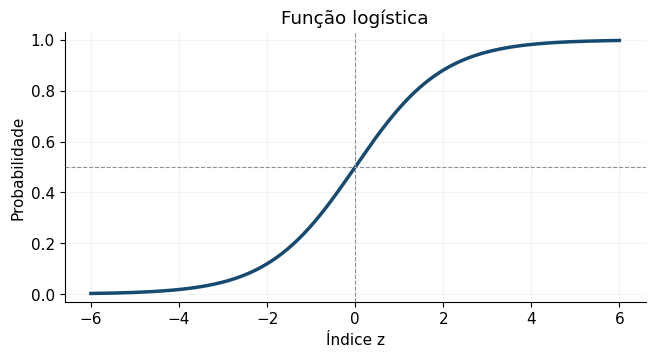

In [4]:
indices = np.array([-4, -2, 0, 2, 4])
display(pd.DataFrame({"Índice z": indices, "Probabilidade logística": expit(indices)}).round(4))

grade_z = np.linspace(-6, 6, 200)
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.plot(grade_z, expit(grade_z), color="#174a70", linewidth=2.5)
ax.axhline(0.5, color="#8c929b", linestyle="--", linewidth=0.8)
ax.axvline(0, color="#8c929b", linestyle="--", linewidth=0.8)
ax.set(xlabel="Índice z", ylabel="Probabilidade", title="Função logística", ylim=(-0.03, 1.03))
ax.grid(alpha=0.15)
plt.show()

### Probabilidade, chances e razão de chances

No cotidiano, usamos “chance” como sinônimo de probabilidade. Aqui vamos separar os conceitos técnicos:

| Conceito | Conta | Exemplo com $p=0{,}8$ |
|---|---|---|
| Probabilidade | $p$ | 80% |
| Chances (*odds*) | $p/(1-p)$ | 4: quatro ocorrências para cada não ocorrência |
| Logaritmo das chances | $\ln[p/(1-p)]$ | $\ln(4)\approx1{,}386$ |

No logit, $p_i/(1-p_i)=\exp(z_i)$. Se um regressor aumenta uma unidade, mantendo os demais constantes, suas chances são multiplicadas por **$\exp(\beta_j)$**, a razão de chances (*odds ratio*). Para PSI, a unidade significa mudar de 0 para 1.

Uma razão de chances de 2 significa dobrar as **odds**, não necessariamente dobrar a probabilidade. Por exemplo, passar de odds 1 para 2 faz a probabilidade passar de 50% para aproximadamente 66,7%.

Por que não transformar simplesmente o $Y$ observado em logaritmo das chances e usar MQO? Para um estudante, $Y$ é 0 ou 1; os logits dessas proporções extremas não são finitos. A discussão de dados agrupados das seções 15.6–15.7 usa proporções de grupos; aqui trabalharemos com os **microdados individuais**, por máxima verossimilhança.

## 3. Estimação por máxima verossimilhança

Uma probabilidade prevista deve ser alta para os resultados que efetivamente ocorreram, dentro do que os dados permitem explicar. Para cada estudante, a contribuição para a verossimilhança é:

- Se obteve A, usamos $p_i$.
- Se não obteve A, usamos $1-p_i$.

Com observações independentes, multiplicamos essas contribuições. O programa procura os coeficientes que maximizam essa expressão; computacionalmente, usa seu logaritmo:

$$\ell(\beta)=\sum_i\{Y_i\ln(p_i)+(1-Y_i)\ln(1-p_i)\}.$$

A rotina numérica está disponível em `statsmodels.Logit`. Usaremos Newton–Raphson para encontrar os coeficientes. Na seção final, veremos por que a log-verossimilhança é negativa, como ela fundamenta o pseudo-R² e como o algoritmo encontra o máximo.

In [5]:
def tabela_inferencia(resultado, nomes):
    return pd.DataFrame({
        "Coeficiente": np.asarray(resultado.params),
        "Erro padrão": np.asarray(resultado.bse),
        "z (H0: coef. = 0)": np.asarray(resultado.tvalues),
        "p-valor": np.asarray(resultado.pvalues),
    }, index=nomes)

In [6]:
# Newton–Raphson procura os coeficientes que maximizam a log-verossimilhança.
# Na seção final, veremos a lógica e as iterações desse algoritmo.
logit = sm.Logit(y, X).fit(method="newton", maxiter=100, tol=1e-10, disp=False)
display(tabela_inferencia(logit, X.columns).style.format("{:.4f}"))
print(f"Convergência: {logit.mle_retvals['converged']} | Log-verossimilhança: {logit.llf:.4f}")
print(f"Menor previsão: {logit.predict(X).min():.4f} | Maior: {logit.predict(X).max():.4f}")

,Coeficiente,Erro padrão,z (H0: coef. = 0),p-valor
const,-13.0213,4.9313,-2.6405,0.0083
GPA,2.8261,1.2629,2.2377,0.0252
TUCE,0.0952,0.1416,0.6722,0.5014
PSI,2.3787,1.0646,2.2344,0.0255


Convergência: True | Log-verossimilhança: -12.8896
Menor previsão: 0.0245 | Maior: 0.9453


Os coeficientes reproduzem a Tabela 15.8 por arredondamento. GPA e PSI têm sinal positivo, enquanto o p-valor de TUCE é mais alto. Um p-valor alto não prova que o efeito seja exatamente zero.

A estatística exibida como `z` é estimativa dividida pelo erro padrão, com referência normal assintótica. Alguns objetos do pacote chamam essa razão de `tvalues`, mas aqui ela não é um teste t exato de pequena amostra. Máxima verossimilhança tem propriedades de grandes amostras; não pressupomos ausência de viés em amostra finita.

## 4. Interpretando o logit

O coeficiente de PSI é aproximadamente 2,379: essa é a diferença no **logaritmo das chances**, e não um aumento de 237,9 pontos percentuais. Vamos exponenciá-lo e depois calcular probabilidades para perfis concretos.

In [7]:
razoes_chances = pd.DataFrame({
    "Coeficiente": logit.params[regressores],
    "Razão de chances exp(coef.)": np.exp(logit.params[regressores]),
})
display(razoes_chances.style.format("{:.4f}"))

perfis = pd.DataFrame({"GPA": [3.2, 3.2], "TUCE": [22, 22], "PSI": [0, 1]},
                      index=["Sem PSI", "Com PSI"])
Xp = sm.add_constant(perfis[regressores], has_constant="add")
perfis["Probabilidade logit"] = logit.predict(Xp)
display(perfis.style.format({"GPA": "{:.1f}", "Probabilidade logit": "{:.2%}"}))
print(f"Diferença prevista: {100 * perfis['Probabilidade logit'].diff().iloc[1]:.2f} pontos percentuais.")

,Coeficiente,Razão de chances exp(coef.)
GPA,2.8261,16.8797
TUCE,0.0952,1.0998
PSI,2.3787,10.7907


,GPA,TUCE,PSI,Probabilidade logit
Sem PSI,3.2,22,0,13.19%
Com PSI,3.2,22,1,62.11%


Diferença prevista: 48.92 pontos percentuais.


A razão de chances de PSI, aproximadamente 10,79, é constante nesta especificação sem interações. A diferença entre probabilidades depende do perfil inicial. Por isso, ela não pode ser lida diretamente do coeficiente ou da razão de chances.

Para um regressor contínuo, a inclinação local da probabilidade é $\beta_jp_i(1-p_i)$. Na próxima aula, calcularemos sistematicamente efeitos marginais e mudanças discretas para comparar os modelos.

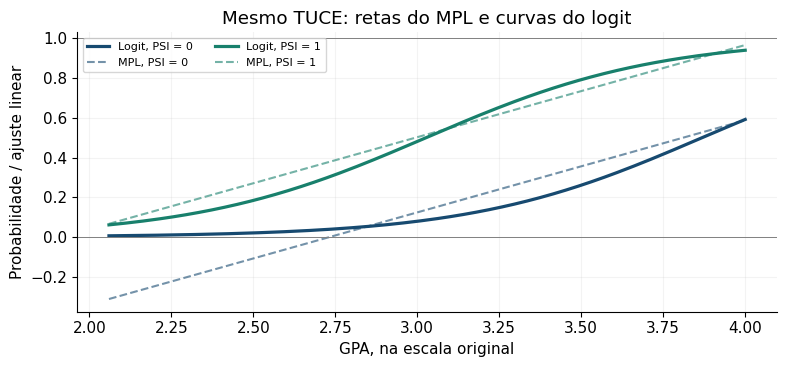

In [8]:
grade_gpa = np.linspace(dados.GPA.min(), dados.GPA.max(), 150)
fig, ax = plt.subplots(figsize=(8, 3.8))
for psi, cor in [(0, "#174a70"), (1, "#18806c")]:
    grade = pd.DataFrame({"GPA": grade_gpa, "TUCE": dados.TUCE.mean(), "PSI": psi})
    Xg = sm.add_constant(grade[regressores], has_constant="add")
    ax.plot(grade_gpa, logit.predict(Xg), color=cor, linewidth=2.3, label=f"Logit, PSI = {psi}")
    ax.plot(grade_gpa, mpl.predict(Xg), color=cor, linestyle="--", alpha=0.6, label=f"MPL, PSI = {psi}")
ax.axhline(0, color="gray", linewidth=0.7)
ax.axhline(1, color="gray", linewidth=0.7)
ax.set(xlabel="GPA, na escala original", ylabel="Probabilidade / ajuste linear",
       title="Mesmo TUCE: retas do MPL e curvas do logit")
ax.legend(fontsize=8, ncol=2, loc="upper left")
ax.grid(alpha=0.15)
fig.tight_layout()
plt.show()

## 5. Pressupostos, consistência e matriz de covariância

Para o logit representar a probabilidade condicional, supomos que a curva logística esteja corretamente especificada e que as relações com os fatores não observados sejam compatíveis com essa especificação. Identificação e condições usuais de amostragem também são necessárias à consistência. A ausência de endogeneidade, sozinha, não determina qual é a função correta para a probabilidade.

No MPL, a inferência clássica de MQO impunha uma variância comum. No logit corretamente especificado, a própria verossimilhança Bernoulli já incorpora $p_i(1-p_i)$. Portanto, essa variância variável não invalida automaticamente a matriz usual do logit.

Podemos calcular também uma matriz **sanduíche HC0** para comparar a incerteza, preservando os coeficientes. A correção não resolve endogeneidade, uma curva de probabilidade inadequada ou falta de identificação. Com apenas 32 alunos, os resultados inferenciais são ilustrativos e aproximados.

In [9]:
logit_robusto = sm.Logit(y, X).fit(method="newton", maxiter=100, tol=1e-10, disp=False, cov_type="HC0")
comparacao_cov = pd.concat({
    "Usual da verossimilhança": tabela_inferencia(logit, X.columns),
    "Sanduíche HC0": tabela_inferencia(logit_robusto, X.columns),
}, names=["Matriz", "Parâmetro"])
display(comparacao_cov.style.format("{:.4f}"))
print("Ao trocar a matriz, preservamos o modelo ajustado e suas probabilidades.")

Ao trocar a matriz, preservamos o modelo ajustado e suas probabilidades.


## 6. Log-verossimilhança, pseudo-R² e Newton–Raphson

### 6.1. Por que a log-verossimilhança vai de menos infinito até zero?

Para cada estudante, o modelo atribui uma probabilidade ao **resultado que efetivamente ocorreu**:

$$q_i=\begin{cases}
p_i,&\text{se }Y_i=1,\\
1-p_i,&\text{se }Y_i=0.
\end{cases}$$

Se um estudante obteve A, queremos que $p_i$ seja alta. Se não obteve A, queremos que $1-p_i$ seja alta.
Por exemplo, atribuir probabilidade $0{,}01$ ao resultado observado produz uma contribuição
$\ln(0{,}01)\approx-4{,}605$; atribuir $0{,}90$ produz $\ln(0{,}90)\approx-0{,}105$.
O segundo resultado está mais perto de zero e contribui mais para a log-verossimilhança.

Com observações independentes, a verossimilhança é a probabilidade conjunta dos resultados observados:

$$L(\beta)=\prod_{i=1}^{n}q_i,
\qquad \ell(\beta)=\ln L(\beta)=\sum_{i=1}^{n}\ln q_i.$$

Como cada $q_i$ fica entre zero e um, $L$ também fica nesse intervalo. O logaritmo é crescente, de modo
que **maximizar $L$ e maximizar $\ell$ leva aos mesmos coeficientes**. A transformação muda a escala:

$$L\longrightarrow0^+\ \Rightarrow\ \ell\longrightarrow-\infty,
\qquad L\longrightarrow1\ \Rightarrow\ \ell\longrightarrow0.$$

**Zero é o máximo teórico da escala:** $\ln(1)=0$. Para chegar a ele, todos os resultados observados
precisariam receber probabilidade um: $p_i=1$ para quem obteve A e $p_i=0$ para os demais.
Esse é o ajuste perfeito de um modelo saturado para estes dados Bernoulli individuais.
Com coeficientes finitos, a função logística mantém $0<p_i<1$, portanto $\ell(\beta)<0$.

No logit com intercepto, GPA, TUCE e PSI, procuramos o **maior valor permitido por essa especificação**.
Nesta amostra, o máximo é negativo. O zero funciona como teto de referência; sua existência não significa
que o modelo estimado consiga atingi-lo. Em casos de separação perfeita, a aproximação a zero pode exigir
coeficientes de magnitude crescente, sem um máximo finito.

O gráfico seguinte mostra a transformação $\ell=\ln L$. Seu eixo horizontal é a verossimilhança $L$;
mais adiante veremos uma curva em função dos coeficientes.

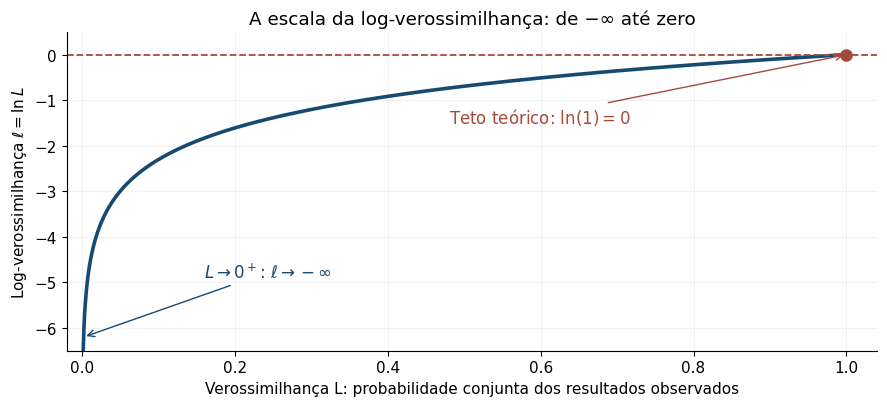

A curva continua para baixo: −∞ é um limite, não um valor finito no eixo.
O ponto em L = 1 representa o teto do ajuste perfeito.


In [10]:
# O zero pertence ao teto teórico. Para desenhar a curva, usamos L > 0.
valores_L = np.linspace(0.00001, 1, 1200)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(valores_L, np.log(valores_L), color="#174a70", linewidth=2.6)
ax.axhline(0, color="#a64b3c", linestyle="--", linewidth=1.3)
ax.scatter([1], [0], color="#a64b3c", s=65, zorder=4)

ax.annotate(
    r"$L \to 0^+$: $\ell \to -\infty$",
    xy=(0.002, -6.2), xytext=(0.16, -4.9),
    arrowprops={"arrowstyle": "->", "color": "#174a70"},
    color="#174a70", fontsize=12
)
ax.annotate(
    r"Teto teórico: $\ln(1)=0$",
    xy=(1, 0), xytext=(0.48, -1.5),
    arrowprops={"arrowstyle": "->", "color": "#a64b3c"},
    color="#a64b3c", fontsize=12
)
ax.set(
    xlabel="Verossimilhança L: probabilidade conjunta dos resultados observados",
    ylabel=r"Log-verossimilhança $\ell=\ln L$",
    title="A escala da log-verossimilhança: de −∞ até zero",
    xlim=(-0.02, 1.04), ylim=(-6.5, 0.5)
)
ax.grid(alpha=0.16)
fig.tight_layout()
plt.show()

print("A curva continua para baixo: −∞ é um limite, não um valor finito no eixo.")
print("O ponto em L = 1 representa o teto do ajuste perfeito.")

### 6.2. O pseudo-R² como uma distância percorrida até zero

Precisamos de uma referência para avaliar o ganho obtido com os regressores. No **modelo nulo**, estimamos
apenas o intercepto. Todos os estudantes recebem a mesma probabilidade prevista, $\bar Y$:

$$\widehat\beta_{\mathrm{nulo}}=
\left(\ln\frac{\bar Y}{1-\bar Y},\ 0,\ 0,\ 0\right)'. $$

O intercepto é estimado; ele não precisa ser zero. Se todos os coeficientes fossem zero,
a probabilidade seria $0{,}5$, que só coincide com $\bar Y$ em uma amostra com metade de sucessos.

Chamaremos de $\ell_0$ a log-verossimilhança do modelo nulo e de $\ell_1$ a log-verossimilhança do
logit com GPA, TUCE e PSI. Como o modelo com regressores inclui o modelo nulo como caso particular,
sua maximização na mesma amostra permite obter $\ell_0\leq\ell_1<0$ neste exemplo.

O **pseudo-R² de McFadden** é:

$$R^2_{\mathrm{McF}}=1-\frac{\ell_1}{\ell_0}
=\frac{\ell_1-\ell_0}{0-\ell_0}.$$

A última expressão permite ler o gráfico diretamente:

- **Numerador:** ganho de log-verossimilhança, do modelo nulo até o modelo com regressores.
- **Denominador:** distância total do modelo nulo até o teto teórico zero.

Assim, o pseudo-R² mede a **fração dessa distância que foi percorrida**. Se $\ell_1=\ell_0$, ele vale zero.
Se $\ell_1$ se aproxima de zero, ele se aproxima de um. A faixa de zero a um usa aqui os mesmos dados,
o intercepto e a maximização dos modelos comparados.

Um valor próximo de $0{,}374$ significa uma redução de aproximadamente 37,4% na distância de
log-verossimilhança até o ajuste perfeito, tomando o modelo nulo como referência. **Isso não é
a proporção da variância de Y explicada nem o percentual de estudantes classificados corretamente.**

Referência,Log-verossimilhança,Distância até zero
Só intercepto,-20.5917,20.5917
"GPA, TUCE e PSI",-12.8896,12.8896
Ajuste perfeito: teto teórico,0.0000,0.0000


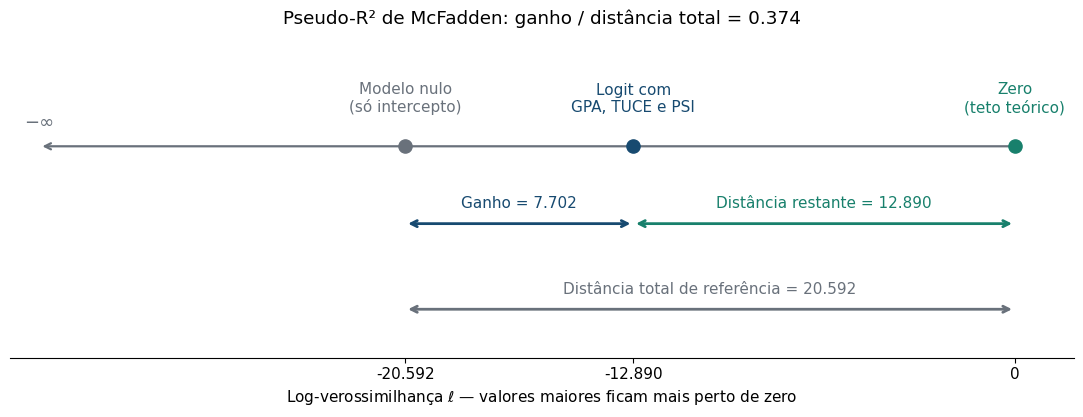

Probabilidade do modelo nulo: 34.38% para todos os estudantes.
Pseudo-R² = (-12.8896 − (-20.5917)) / (0 − (-20.5917)) = 0.3740 (37.40%).
O atributo logit.prsquared devolve a mesma medida: 0.3740.


In [11]:
# Estimamos o modelo de referência: somente o intercepto.
X_nulo = pd.DataFrame({"const": np.ones(len(y))}, index=y.index)
logit_nulo = sm.Logit(y, X_nulo).fit(method="newton", disp=False, tol=1e-10)

ell_nulo = float(logit_nulo.llf)
ell_ajustado = float(logit.llf)
ganho_logverossimilhanca = ell_ajustado - ell_nulo
distancia_ate_zero = 0 - ell_nulo
distancia_restante = 0 - ell_ajustado
pseudo_r2_mcfadden = ganho_logverossimilhanca / distancia_ate_zero

resumo_ajuste = pd.DataFrame({
    "Referência": ["Só intercepto", "GPA, TUCE e PSI", "Ajuste perfeito: teto teórico"],
    "Log-verossimilhança": [ell_nulo, ell_ajustado, 0],
    "Distância até zero": [-ell_nulo, -ell_ajustado, 0]
})
display(resumo_ajuste.style.format({
    "Log-verossimilhança": "{:.4f}", "Distância até zero": "{:.4f}"
}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(11, 4.3))

# Uma única escala horizontal para comparar as log-verossimilhanças.
# A seta à esquerda indica que a escala continua até −∞.
limite_esquerdo = 1.60 * ell_nulo
ax.annotate(
    "", xy=(limite_esquerdo, 2), xytext=(0, 2),
    arrowprops={"arrowstyle": "->", "color": "#69717b", "lw": 1.6}
)
ax.text(limite_esquerdo, 2.18, "−∞", ha="center", color="#69717b", fontsize=13)

referencias = [
    (ell_nulo, "Modelo nulo\n(só intercepto)", "#69717b"),
    (ell_ajustado, "Logit com\nGPA, TUCE e PSI", "#174a70"),
    (0, "Zero\n(teto teórico)", "#18806c")
]
for valor, rotulo, cor in referencias:
    ax.scatter(valor, 2, s=90, color=cor, zorder=4)
    ax.text(valor, 2.30, rotulo, ha="center", va="bottom", color=cor, fontsize=11)

def marcar_distancia(inicio, fim, altura, texto, cor):
    ax.annotate(
        "", xy=(inicio, altura), xytext=(fim, altura),
        arrowprops={"arrowstyle": "<->", "color": cor, "lw": 2}
    )
    ax.text((inicio + fim) / 2, altura + 0.15, texto, ha="center", color=cor, fontsize=11)

marcar_distancia(
    ell_nulo, ell_ajustado, 1.25,
    f"Ganho = {ganho_logverossimilhanca:.3f}", "#174a70"
)
marcar_distancia(
    ell_ajustado, 0, 1.25,
    f"Distância restante = {distancia_restante:.3f}", "#18806c"
)
marcar_distancia(
    ell_nulo, 0, 0.42,
    f"Distância total de referência = {distancia_ate_zero:.3f}", "#69717b"
)

ax.set_xticks([ell_nulo, ell_ajustado, 0])
ax.set_xticklabels([f"{ell_nulo:.3f}", f"{ell_ajustado:.3f}", "0"])
ax.set_yticks([])
ax.set(
    xlim=(limite_esquerdo - 1.0, 2.0), ylim=(-0.05, 3.1),
    xlabel=r"Log-verossimilhança $\ell$ — valores maiores ficam mais perto de zero",
    title=f"Pseudo-R² de McFadden: ganho / distância total = {pseudo_r2_mcfadden:.3f}"
)
for borda in ["top", "right", "left"]:
    ax.spines[borda].set_visible(False)
fig.tight_layout()
plt.show()

print(f"Probabilidade do modelo nulo: {y.mean():.2%} para todos os estudantes.")
print(
    f"Pseudo-R² = ({ell_ajustado:.4f} − ({ell_nulo:.4f})) / (0 − ({ell_nulo:.4f}))"
    f" = {pseudo_r2_mcfadden:.4f} ({pseudo_r2_mcfadden:.2%})."
)
print(f"O atributo logit.prsquared devolve a mesma medida: {logit.prsquared:.4f}.")

### 6.3. Onde entra Newton–Raphson?

Para calcular o pseudo-R², precisamos antes encontrar os coeficientes que maximizam $\ell(\beta)$.
As condições de primeira ordem do logit formam um sistema não linear, pois as probabilidades
$p_i=\Lambda(x_i'\beta)$ também dependem dos coeficientes. Não conseguimos isolá-los pela fórmula de MQO.

**Newton–Raphson é usado dentro de `fit(method="newton")` para estimar o vetor de coeficientes.**
O método começa com um palpite, calcula a inclinação e a curvatura da log-verossimilhança nesse ponto
e propõe um novo vetor. Repete o processo até que a alteração dos coeficientes seja suficientemente pequena
ou até alcançar o número máximo de iterações.

A inclinação é o **vetor escore**, e a curvatura é a **matriz Hessiana**:

$$g(\beta)=\frac{\partial\ell}{\partial\beta}=X'(y-p),
\qquad H(\beta)=\frac{\partial^2\ell}{\partial\beta\partial\beta'}=-X'WX,$$

em que $W$ é diagonal, com elementos $p_i(1-p_i)$. O passo de Newton é:

$$\beta^{(k+1)}=\beta^{(k)}-[H(\beta^{(k)})]^{-1}g(\beta^{(k)}).$$

O algoritmo usa a aproximação quadrática local de $\ell$ para procurar um ponto de escore zero.
A forma côncava da log-verossimilhança logística permite identificar o máximo quando ele existe
de forma finita e o modelo está identificado. Embora a expressão use a inversa, a rotina pode calcular
o passo resolvendo o sistema linear correspondente, o que evita formar a inversa explicitamente.

A seguir começaremos no **modelo nulo**: intercepto igual a $\ln[\bar Y/(1-\bar Y)]$ e inclinações iguais
a zero. Usaremos a opção `callback` para guardar os coeficientes depois de cada iteração real da rotina.
O intercepto e os três coeficientes são atualizados simultaneamente.

Depois que o algoritmo encontra $\widehat\beta$, calculamos $\ell(\widehat\beta)$ e a comparamos com
$\ell_0$. **O pseudo-R² é uma conta feita com os valores das log-verossimilhanças já obtidos.**
O algoritmo procura o máximo permitido pelo logit; o teto teórico zero permanece como referência.

In [12]:
modelo_newton = sm.Logit(y, X)

# Partimos das probabilidades constantes do modelo nulo.
beta_inicio = np.zeros(X.shape[1])
beta_inicio[0] = np.log(y.mean() / (1 - y.mean()))
historico_betas = [beta_inicio.copy()]

# O statsmodels chama esta função depois de cada passo de Newton–Raphson.
def registrar_iteracao(beta_atual):
    historico_betas.append(np.asarray(beta_atual).copy())

resultado_newton = modelo_newton.fit(
    start_params=beta_inicio,
    method="newton",          # Aqui o algoritmo é escolhido.
    callback=registrar_iteracao,
    maxiter=100,
    tol=1e-10,
    disp=False
)

# A log-verossimilhança e o escore são avaliados em cada vetor visitado.
caminho_betas = np.vstack(historico_betas)
ell_iteracoes = np.array([modelo_newton.loglike(beta) for beta in caminho_betas])
maior_escore = np.array([
    np.max(np.abs(modelo_newton.score(beta))) for beta in caminho_betas
])

tabela_newton = pd.DataFrame(caminho_betas, columns=X.columns)
tabela_newton.insert(0, "Iteração", np.arange(len(caminho_betas)))
tabela_newton["Log-verossimilhança"] = ell_iteracoes
tabela_newton["Ganho no passo"] = pd.Series(ell_iteracoes).diff()
tabela_newton["Maior |escore|"] = maior_escore

formatos_newton = {coluna: "{:.6f}" for coluna in tabela_newton.columns if coluna != "Iteração"}
display(tabela_newton.style.format(formatos_newton, na_rep="—").hide(axis="index"))
print(f"Convergiu: {resultado_newton.mle_retvals['converged']}.")
print(f"Número de passos de Newton: {resultado_newton.mle_retvals['iterations']}.")
print(f"Log-verossimilhança no máximo: {resultado_newton.llf:.6f}.")
print("O vetor final reproduz a estimação da seção 3, partindo agora do modelo nulo.")

Iteração,const,GPA,TUCE,PSI,Log-verossimilhança,Ganho no passo,Maior |escore|
0,-0.646627,0.000000,0.000000,0.000000,-20.591730,—,17.687500
1,-8.810997,2.056208,0.046524,1.678096,-13.496795,7.094934,23.281779
2,-11.822081,2.612280,0.080179,2.182489,-12.929189,0.567607,4.538439
3,-12.911042,2.806240,0.093788,2.361023,-12.889942,0.039247,0.357652
4,-13.020386,2.825937,0.095146,2.378536,-12.889634,0.000308,0.002976
5,-13.021347,2.826113,0.095158,2.378688,-12.889634,0.000000,0.000000
6,-13.021347,2.826113,0.095158,2.378688,-12.889634,0.000000,0.000000
7,-13.021347,2.826113,0.095158,2.378688,-12.889634,0.000000,0.000000


Convergiu: True.
Número de passos de Newton: 7.
Log-verossimilhança no máximo: -12.889634.
O vetor final reproduz a estimação da seção 3, partindo agora do modelo nulo.


### 6.4. A curva que maximizamos e o caminho do algoritmo

O vetor $\beta$ tem quatro componentes, por isso não cabe inteiro em um gráfico bidimensional.
No painel da esquerda, desenhamos um **corte da função** ao longo da reta que passa pelo modelo nulo
e pelo vetor estimado:

$$\beta(s)=\beta_{\mathrm{nulo}}+s(\widehat\beta-\beta_{\mathrm{nulo}}).$$

Em $s=0$, estamos no modelo nulo. Em $s=1$, estamos no logit estimado. Valores diferentes de $s$
mudam o intercepto e as inclinações conjuntamente. Essa curva mostra que existe um ponto mais alto
**abaixo de zero**; o teto teórico não precisa ser alcançado pela função que estamos maximizando.

No painel da direita, cada ponto é uma **iteração real de Newton–Raphson** do código anterior.
Aqui, o eixo horizontal é o número da iteração. Os vetores intermediários podem seguir trajetórias
diferentes da reta usada no painel da esquerda. Nesta amostra, a log-verossimilhança aumenta e
se estabiliza no máximo. O tamanho dos passos e esse comportamento dependem do problema e do ponto inicial.

A leitura da tabela acompanha o gráfico: perto da convergência, os coeficientes quase não mudam,
o ganho de log-verossimilhança fica próximo de zero e o escore também se aproxima de zero.

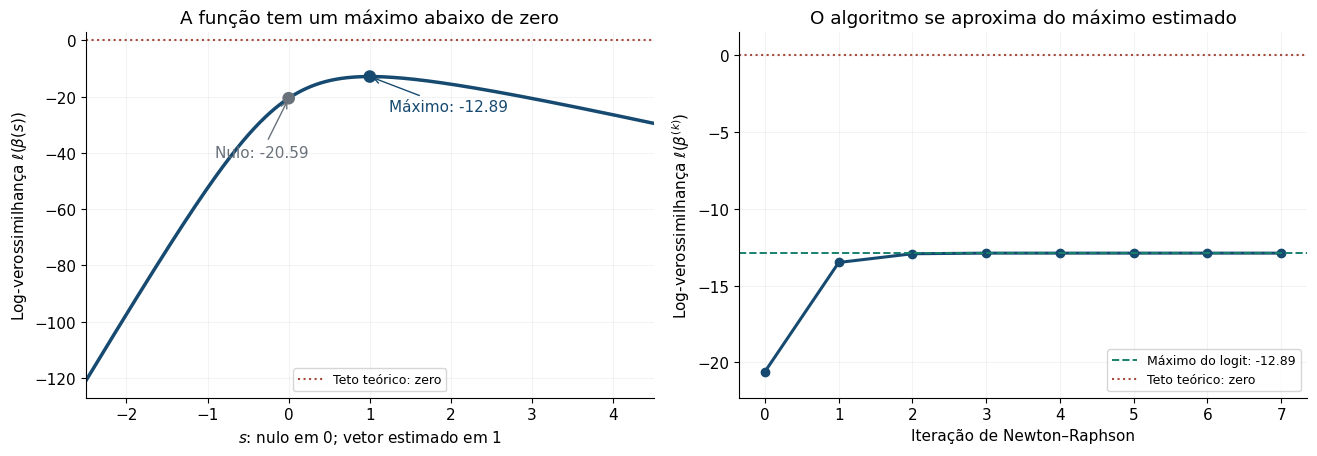

O teto é zero, mas o máximo deste logit é -12.8896.
Do nulo até esse máximo, percorremos 37.40% da distância até zero.


In [13]:
# Corte da log-verossimilhança na direção do nulo até o vetor estimado.
direcao = np.asarray(resultado_newton.params) - beta_inicio
grade_s = np.linspace(-2.5, 4.5, 500)
ell_corte = np.array([
    modelo_newton.loglike(beta_inicio + s * direcao) for s in grade_s
])

fig, (ax_curva, ax_passos) = plt.subplots(1, 2, figsize=(13.3, 4.7))

# Painel 1: função-objetivo em um corte do espaço dos coeficientes.
ax_curva.plot(grade_s, ell_corte, color="#174a70", linewidth=2.5)
ax_curva.axhline(0, color="#a64b3c", linestyle=":", linewidth=1.5, label="Teto teórico: zero")
ax_curva.scatter([0, 1], [ell_nulo, ell_ajustado], color=["#69717b", "#174a70"], s=65, zorder=4)
ax_curva.annotate(
    f"Nulo: {ell_nulo:.2f}", xy=(0, ell_nulo), xytext=(-53, -42),
    textcoords="offset points", arrowprops={"arrowstyle": "->", "color": "#69717b"},
    color="#69717b"
)
ax_curva.annotate(
    f"Máximo: {ell_ajustado:.2f}", xy=(1, ell_ajustado), xytext=(14, -25),
    textcoords="offset points", arrowprops={"arrowstyle": "->", "color": "#174a70"},
    color="#174a70"
)
ax_curva.set(
    xlabel=r"$s$: nulo em 0; vetor estimado em 1",
    ylabel=r"Log-verossimilhança $\ell(\beta(s))$",
    title="A função tem um máximo abaixo de zero",
    xlim=(grade_s.min(), grade_s.max()), ylim=(ell_corte.min() * 1.05, 3)
)
ax_curva.legend(loc="lower center", fontsize=9)

# Painel 2: valores efetivamente visitados pelo algoritmo.
iteracoes = np.arange(len(ell_iteracoes))
ax_passos.plot(iteracoes, ell_iteracoes, "o-", color="#174a70", linewidth=2.2, markersize=6)
ax_passos.axhline(
    ell_ajustado, color="#18806c", linestyle="--", linewidth=1.4,
    label=f"Máximo do logit: {ell_ajustado:.2f}"
)
ax_passos.axhline(
    0, color="#a64b3c", linestyle=":", linewidth=1.5, label="Teto teórico: zero"
)
ax_passos.set_xticks(iteracoes)
ax_passos.set(
    xlabel="Iteração de Newton–Raphson",
    ylabel=r"Log-verossimilhança $\ell(\beta^{(k)})$",
    title="O algoritmo se aproxima do máximo estimado",
    ylim=(ell_nulo - 1.7, 1.5)
)
ax_passos.legend(loc="lower right", fontsize=9)

for ax in [ax_curva, ax_passos]:
    ax.grid(alpha=0.15)
fig.tight_layout()
plt.show()

print(f"O teto é zero, mas o máximo deste logit é {ell_ajustado:.4f}.")
print(f"Do nulo até esse máximo, percorremos {pseudo_r2_mcfadden:.2%} da distância até zero.")

**Documentação das rotinas utilizadas:**
[estimação do Logit e escolha de Newton–Raphson](https://www.statsmodels.org/stable/generated/statsmodels.discrete.discrete_model.Logit.fit.html),
[log-verossimilhança do Logit](https://www.statsmodels.org/stable/generated/statsmodels.discrete.discrete_model.Logit.loglike.html) e
[pseudo-R² de McFadden em `prsquared`](https://www.statsmodels.org/stable/generated/statsmodels.discrete.discrete_model.LogitResults.prsquared.html).